[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/01-agent-that-sees/01-agent-that-sees.ipynb)

# 01 · An Agent That Sees

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*

## What you will learn
- Ground every visual claim in a named region — no floating assertions.
- Attach a confidence to each claim, and learn why low-confidence claims are flagged, not hidden.
- Compute a *survival rate* from a verification table — and see why, in this scripted demo, that rate is an illustration, not a measurement: the verification column is the author's recorded judgement on synthetic scenes, kept in the data file.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and §7 compares them with the recorded run evidence shipped in this repository. Work the exercises in §8 with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 0 · Why this matters — the market in numbers

- **The market:** enterprise agentic AI software is forecast from **$2.58B (2024) to $24.5B (2030)**, a 46.2% CAGR — Grand View Research, Enterprise Agentic AI Market Report 2025–2030.
- **The adoption wave:** Gartner (Aug 2025) predicts **40% of enterprise applications will feature task-specific AI agents by end of 2026**, up from under 5% in 2025.
- **The failure curve:** Gartner (Jun 2025) predicts **over 40% of agentic AI projects will be cancelled by end of 2027** — on escalating costs, unclear business value or inadequate risk controls.

Inadequate risk controls are a named cause on that failure curve. This POC's answer is a verification loop: a perception claim that cannot name its evidence region and survive a checker is exactly the kind of output that gets a pilot cancelled.

*Sources: Grand View Research (2025); Gartner press releases, Jun 2025 and 2025-08-26. These are market forecasts, cited as market data — the results inside this notebook are a scripted demonstration and are labelled ILLUSTRATIVE.*

## 1 · The idea

**Idea:** Audit public spaces for accessibility barriers from photos, with every finding pinned to a region.
**Build steps:** (1) Define synthetic scenes as regions with ground-truth objects. (2) Stub parser emits region-grounded claims + confidence per region. (3) Flag claims under 0.60 as GUESS. (4) Human verification recorded against ground truth; survival rate computed.
**Guardrail:** Findings are drafts until a human confirms them on the image.
**Win condition:** Every reported barrier points at the region that proves it; the survival rate is computed from the verification table, never asserted — in this scripted demo that table is typed in the script, so the rate illustrates the method; against human checkers it becomes a measurement.
Data: synthetic only. Model: deterministic stub, no live model.

## 2 · How it is built

Built: `poc/sees.py` — a layered scene parser over three synthetic scenes (pavement, entrance, crossing), 13 region claims.
Design: PERCEIVE (regions) → RELATE (region labels carry spatial relations) → INTERPRET (accessibility-relevant objects named) → VERIFY (recorded human check per claim).
Data: `data/claims.csv` is the input of record — scenes, claims, confidences and the recorded human verification live in the data file; the code derives each flag from its confidence and computes the survival rate. Perturbation test: `tests/test_perturbation.py`.
Run: `python3 poc/sees.py` → `runs/run-01.json`.
Shared kit: none required for this minimal build; transcript/termination primitives are introduced in POCs 02–03 and reused later.

**Execution flow** (version of record: `diagrams/TECHNICAL-FLOWS.md`):

```mermaid
%%{init: {"flowchart": {"nodeSpacing": 28, "rankSpacing": 44, "padding": 12}}}%%
flowchart LR
    A(["1 · Load scenes<br/>3 synthetic + truth"]):::io --> B["2 · Emit claims<br/>object + confidence"]:::proc
    B --> C{"3 · ≥ 0.60?"}:::decision
    C -->|yes| D["GROUNDED"]:::proc
    C -->|no| E["GUESS"]:::warn
    D --> F["4 · Verify<br/>vs ground truth"]:::proc
    E --> F
    F --> G(["5 · Survival rate<br/>+ claims.csv"]):::metric
    classDef io fill:#1A1A2E,stroke:#C9A227,stroke-width:2px,color:#FFFFFF;
    classDef proc fill:#E6F4F6,stroke:#1B9AAA,stroke-width:1.5px,color:#123B40;
    classDef decision fill:#FBF3D9,stroke:#C9A227,stroke-width:2px,color:#5A4A00;
    classDef warn fill:#FBE9E7,stroke:#C1666B,stroke-width:1.5px,color:#6E2B26;
    classDef metric fill:#1B9AAA,stroke:#146B76,stroke-width:2px,color:#FFFFFF;
```

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline).

In [2]:
"""POC 01 - An Agent That Sees: layered scene parser (deterministic stub).
Synthetic scenes only. The scenes, the parser's claims and confidences,
and the recorded human verification live in data/claims.csv - the data
file is the input of record. This module loads it, derives each claim's
flag from its confidence (below 0.60 = GUESS, the confidence map) and
computes the survival rate from the verification column. Edit the CSV
and every figure in the run moves.
"""
import csv
import json
from pathlib import Path

FLAG_THRESHOLD = 0.60

def parse_claims(text):
    """Parse claims CSV text -> rows with the flag derived from confidence."""
    rows = []
    for r in csv.DictReader(text.splitlines()):
        confidence = float(r["confidence"])
        rows.append({"scene": r["scene"], "region": r["region"],
                     "claim": r["claim"], "confidence": confidence,
                     "flag": "GUESS" if confidence < FLAG_THRESHOLD else "GROUNDED",
                     "verified": r["verified"].strip().lower() == "true"})
    return rows

def load_claims(path):
    return parse_claims(Path(path).read_text(encoding="utf-8"))

def summarise(rows):
    survived = sum(1 for r in rows if r["verified"])
    return {"claims": rows, "total": len(rows), "survived": survived,
            "survival_rate": round(survived / len(rows), 3)}

def main():
    base = Path(".")  # notebook context: this folder (the notebook folder in the repo)
    print(json.dumps(summarise(load_claims(base / "data" / "claims.csv")), indent=2))

if __name__ == "__main__":
    main()

{
  "claims": [
    {
      "scene": "pavement-01",
      "region": "top-left",
      "claim": "pavement slab",
      "confidence": 0.97,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "centre",
      "claim": "crack, 18mm at widest",
      "confidence": 0.91,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "centre-right",
      "claim": "raised edge, trip hazard",
      "confidence": 0.84,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "bottom",
      "claim": "drain cover",
      "confidence": 0.95,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "top-right (occluded)",
      "claim": "possible bollard base",
      "confidence": 0.42,
      "flag": "GUESS",
      "verified": false
    },
    {
      "scene": "entrance-02",
      "region": "centre

## 5 · Run it

In [3]:
main()

{
  "claims": [
    {
      "scene": "pavement-01",
      "region": "top-left",
      "claim": "pavement slab",
      "confidence": 0.97,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "centre",
      "claim": "crack, 18mm at widest",
      "confidence": 0.91,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "centre-right",
      "claim": "raised edge, trip hazard",
      "confidence": 0.84,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "bottom",
      "claim": "drain cover",
      "confidence": 0.95,
      "flag": "GROUNDED",
      "verified": true
    },
    {
      "scene": "pavement-01",
      "region": "top-right (occluded)",
      "claim": "possible bollard base",
      "confidence": 0.42,
      "flag": "GUESS",
      "verified": false
    },
    {
      "scene": "entrance-02",
      "region": "centre

### Change one outcome — watch the headline move

The survival rate is computed from `data/claims.csv` — the scenes, the confidences and the recorded verification all live in that data file, and the code only computes. In this scripted demo the verification column is the author's recorded judgement on synthetic scenes, which is exactly why the rate is labelled ILLUSTRATIVE, not measured. Flip one outcome in the data and watch the headline move: a metric is only ever as honest as the data behind it.

In [4]:
from pathlib import Path
_csv = Path("data/claims.csv")
_rows = load_claims(_csv) if _csv.exists() else parse_claims('scene,region,claim,confidence,flag,verified\npavement-01,top-left,pavement slab,0.97,GROUNDED,True\npavement-01,centre,"crack, 18mm at widest",0.91,GROUNDED,True\npavement-01,centre-right,"raised edge, trip hazard",0.84,GROUNDED,True\npavement-01,bottom,drain cover,0.95,GROUNDED,True\npavement-01,top-right (occluded),possible bollard base,0.42,GUESS,False\nentrance-02,centre,"step, no ramp",0.93,GROUNDED,True\nentrance-02,left,"handrail, one side only",0.88,GROUNDED,True\nentrance-02,right,"door, manual, heavy",0.71,GROUNDED,True\nentrance-02,top (small print),sign text unreadable,0.35,GUESS,False\ncrossing-03,centre,dropped kerb present,0.96,GROUNDED,True\ncrossing-03,left,tactile paving,0.9,GROUNDED,True\ncrossing-03,right,parked bicycle obstructing kerb,0.78,GROUNDED,True\ncrossing-03,far side (occluded),possible second obstruction,0.48,GUESS,False\n')
_base = summarise(_rows)
_flipped = [dict(r) for r in _rows]
next(r for r in _flipped if r["scene"] == "pavement-01" and r["region"] == "centre")["verified"] = False
_moved = summarise(_flipped)
print("survival from the data as recorded: %d/%d = %.3f" % (_base["survived"], _base["total"], _base["survival_rate"]))
print("after flipping one outcome in the data: %d/%d = %.3f" % (_moved["survived"], _moved["total"], _moved["survival_rate"]))
print("Same code, same scenes - the headline moved because the data moved.")

survival from the data as recorded: 10/13 = 0.769
after flipping one outcome in the data: 9/13 = 0.692
Same code, same scenes - the headline moved because the data moved.


## 6 · See the evidence

The chart is drawn **live** from the recorded run data (`data/claims.csv` in the repository; embedded below as a fallback so the notebook is standalone).

      scene               region                           claim  confidence     flag  verified
pavement-01             top-left                   pavement slab        0.97 GROUNDED      True
pavement-01               centre           crack, 18mm at widest        0.91 GROUNDED      True
pavement-01         centre-right        raised edge, trip hazard        0.84 GROUNDED      True
pavement-01               bottom                     drain cover        0.95 GROUNDED      True
pavement-01 top-right (occluded)           possible bollard base        0.42    GUESS     False
entrance-02               centre                   step, no ramp        0.93 GROUNDED      True
entrance-02                 left         handrail, one side only        0.88 GROUNDED      True
entrance-02                right             door, manual, heavy        0.71 GROUNDED      True
entrance-02    top (small print)            sign text unreadable        0.35    GUESS     False
crossing-03               centre        

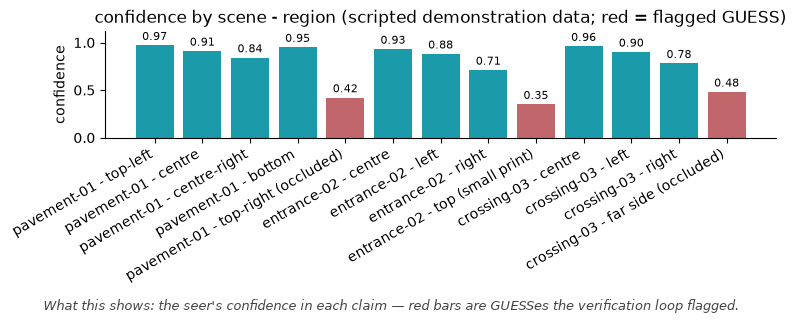

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep sandbox paths/warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """scene,region,claim,confidence,flag,verified
pavement-01,top-left,pavement slab,0.97,GROUNDED,True
pavement-01,centre,"crack, 18mm at widest",0.91,GROUNDED,True
pavement-01,centre-right,"raised edge, trip hazard",0.84,GROUNDED,True
pavement-01,bottom,drain cover,0.95,GROUNDED,True
pavement-01,top-right (occluded),possible bollard base,0.42,GUESS,False
entrance-02,centre,"step, no ramp",0.93,GROUNDED,True
entrance-02,left,"handrail, one side only",0.88,GROUNDED,True
entrance-02,right,"door, manual, heavy",0.71,GROUNDED,True
entrance-02,top (small print),sign text unreadable,0.35,GUESS,False
crossing-03,centre,dropped kerb present,0.96,GROUNDED,True
crossing-03,left,tactile paving,0.9,GROUNDED,True
crossing-03,right,parked bicycle obstructing kerb,0.78,GROUNDED,True
crossing-03,far side (occluded),possible second obstruction,0.48,GUESS,False"""

csv_file = Path("data/claims.csv")
text = csv_file.read_text() if csv_file.exists() else RECORDED_CSV
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "claims"
if CHART_MODE == "claims":
    labels = df["scene"] + " - " + df["region"]
    colors = ["#C1666B" if f == "GUESS" else "#1B9AAA" for f in df["flag"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    bars = ax.bar(labels, df["confidence"], color=colors)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("confidence")
    ax.set_title("confidence by scene - region (scripted demonstration data; red = flagged GUESS)")
    plt.xticks(rotation=30, ha="right")
elif CHART_MODE == "lint":
    df["issues"] = df["lint_result"].apply(lambda s: 0 if s == "CLEAN" else len(s.split(";")))
    ax = df.plot.bar(x="contract", y="issues", legend=False, color="#1B9AAA",
                     figsize=(8, 3.2), title="lint issues by contract (scripted demonstration data)")
    ax.set_ylabel("issues")
    ax.set_ylim(0, 4)
    for t in ax.get_xticklabels():
        t.set_rotation(30); t.set_ha("right")
    ax.bar_label(ax.containers[0], fmt="%d", fontsize=9, padding=2)
else:
    numeric = df.select_dtypes("number").columns.tolist()
    if numeric:
        col = numeric[0]
        labels = df.columns[0]
        ax = df.plot.bar(x=labels, y=col, legend=False, color="#1B9AAA",
                         figsize=(8, 3.2), title=col + " by " + str(labels) + " (scripted demonstration data)")
        ax.set_ylabel(col)
        for t in ax.get_xticklabels():
            t.set_rotation(30); t.set_ha("right")
        ax.bar_label(ax.containers[0], fmt="%d", fontsize=9, padding=2)
        ax.set_ylim(0, df[col].max() * 1.25)
for _a in [ax]:
    _a.spines[['top', 'right']].set_visible(False)
CAPTIONS = {"claims": "What this shows: the seer's confidence in each claim — red bars are GUESSes the verification loop flagged.",
            "lint": "What this shows: lint issues per contract — the good contract passes clean (0); the bad one is stopped before runtime.",
            "bars": "What this shows: messages exchanged per task — the transcript is the coordination record, counted end to end."}
fig = ax.figure
fig.text(0.5, 0.015, CAPTIONS[CHART_MODE], ha="center", fontsize=9, style="italic", color="#444444")
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

## 7 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.json` (executed 2026-10-25, deterministic stub, synthetic scenes); the verification outcomes are fixed in the script, so no figure here is a field measurement.

- Total region claims: 13
- Survived verification: 10 (the check is scripted in this demo — outcomes fixed in poc/sees.py; against human checkers this line is where a measurement would land)
- Survival rate: 0.769
- All 3 failed claims were flagged GUESS (confidence 0.42, 0.35, 0.48 — occlusion / small print), in this scripted demonstration the verification outcomes are fixed in the script (poc/sees.py), so the separation holds by construction — the run illustrates the pattern; it is not a measured result.
- Data table: `data/claims.csv` (ILLUSTRATIVE). Chart: drawn live in the notebook from that table (ILLUSTRATIVE).

## 8 · Exercises

1. Add a fourth synthetic scene of your own (a bus stop, a clinic entrance). Before running, predict which regions will fall below 0.60 — then check your prediction against the flag rule.
2. Raise the GUESS threshold from 0.60 to 0.75. How many claims change class? Which verified claims would you now be discarding — and what does that teach about threshold-setting?
3. The stub is deterministic. Sketch (in words or code) what changes when a live vision model replaces it: which parts of this notebook stay identical, and which become probabilistic?

## 9 · Recap

A seeing agent earns trust the same way any witness does: it shows where it looked, says how sure it is, and submits to verification. Here the scenes and the verification column are scripted demonstration data, so the survival rate illustrates the method; with a live model and human checkers, the same computation becomes a measurement.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*